In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().resolve()
if project_root.name == "multiscale_implementation":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from multiscale_implementation.data_loading.config import Config
from multiscale_implementation.nn_model.training import train

In [2]:
path = "/localdata/tomfre/Poisson/"
data_case = "poisson_f=random_g=zero_domain=unit_square_mesh_res=32_neumann=False"

config = Config(
    data_dir = path+data_case,  # folder with your sample_XXXX.pt files
    pattern = "sample_*.pt",
    val_fraction = 0.1, # fraction of samples for validation
    edge_dim = 3,  # edge features: (dx, dy, |d|) / mean edge length of this level
    hidden = 16,  # latent width; 128 is more accurate but ~3x slower
    n_levels = 4,  # number of graph levels incl. the original mesh
    mp_per_level = 2,  # message-passing blocks per level (down and up)
    out_dim = 1,  # number of output features per node (1 for Poisson)
    use_pos = 1,  # 1: give (x, y) as node input; 0: geometry only via edges
    batch_size = 32,
    epochs = 200,
    lr = 1e-3,
    weight_decay = 0.0,
    seed = 0,
    device = "cuda:3",
    save = "poisson_msgnn.pt",
    plot_hierarchy="hierarchy.png"
)

450 train / 50 val samples, 1 distinct mesh(es)
hierarchy: 1089 nodes/6272 edges -> 121 nodes/640 edges -> 16 nodes/66 edges -> 4 nodes/10 edges
scales: f=10 g=1e-08 u=0.109
model parameters: 31,537
epoch    1  train relL2 1.0292  val relL2 0.9821  (2s)
epoch   10  train relL2 0.6484  val relL2 0.5760  (7s)
epoch   20  train relL2 0.4512  val relL2 0.5086  (13s)
epoch   30  train relL2 0.3864  val relL2 0.3116  (18s)
epoch   40  train relL2 0.3778  val relL2 0.2692  (24s)
epoch   50  train relL2 0.2205  val relL2 0.2158  (30s)
epoch   60  train relL2 0.2531  val relL2 0.2999  (36s)
epoch   70  train relL2 0.2026  val relL2 0.1947  (42s)
epoch   80  train relL2 0.1487  val relL2 0.2396  (47s)
epoch   90  train relL2 0.1260  val relL2 0.1265  (53s)
epoch  100  train relL2 0.1408  val relL2 0.1479  (59s)
epoch  110  train relL2 0.1252  val relL2 0.1413  (65s)
epoch  120  train relL2 0.1037  val relL2 0.1265  (71s)
epoch  130  train relL2 0.0997  val relL2 0.1091  (76s)
epoch  140  train r

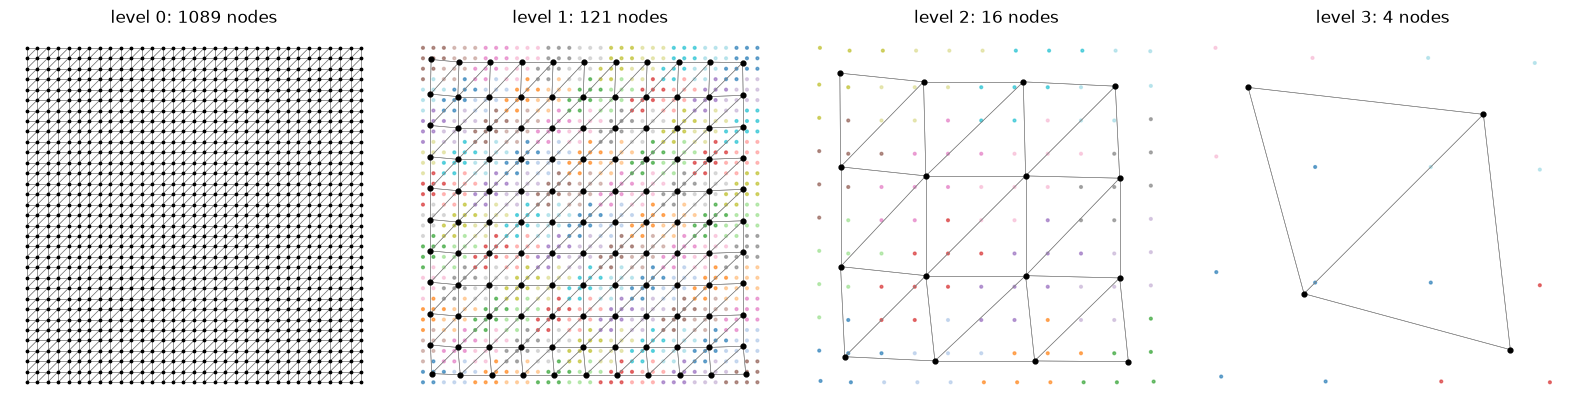

In [3]:
model, scales, meshbank = train(config)

Prediction: min=-0.1928, max=0.1054
Real Solution: min=-0.1931, max=0.1099
Absolute Error: min=0.0000, max=0.0185


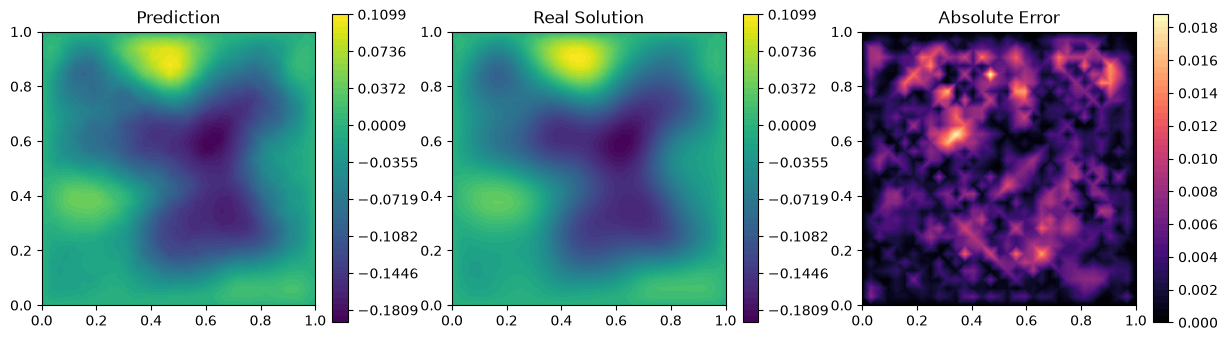

In [17]:
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import random
import torch

from multiscale_implementation.data_loading.loading import load_folder
from multiscale_implementation.data_loading.normalization import node_features
from multiscale_implementation.nn_model.model import predict

plot_samples = load_folder(config.data_dir, config.pattern)
random.Random(config.seed).shuffle(plot_samples)
n_val = max(1, int(config.val_fraction * len(plot_samples)))
sample = plot_samples[:n_val][5]
device = next(model.parameters()).device
x = node_features(sample, scales, bool(config.use_pos)).unsqueeze(0).to(device)
g = sample["g"].unsqueeze(0).to(device)
bmask = sample["bmask"].unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    prediction = predict(model, x, g, bmask, meshbank.get(sample), scales)

pred = prediction.squeeze().cpu()
true = sample["u"].cpu()
xy = sample["coords"].cpu()
tri = mtri.Triangulation(xy[:, 0], xy[:, 1])
vmin = min(pred.min().item(), true.min().item())
vmax = max(pred.max().item(), true.max().item())
levels = torch.linspace(vmin, vmax, 51)

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, values, title, contour_levels, cmap in [
    (axs[0], pred, "Prediction", levels, "viridis"),
    (axs[1], true, "Real Solution", levels, "viridis"),
    (axs[2], (pred - true).abs(), "Absolute Error", 50, "magma"),
]:
    contour = ax.tricontourf(tri, values, levels=contour_levels, cmap=cmap)
    fig.colorbar(contour, ax=ax)
    ax.set_title(title)
    ax.set_aspect("equal")
    print(f"{title}: min={values.min().item():.4f}, max={values.max().item():.4f}")

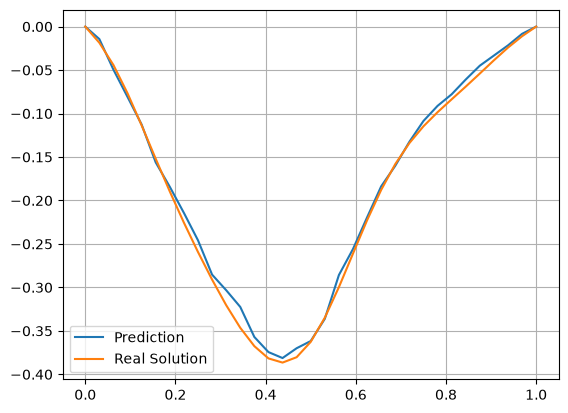

In [16]:
mask = torch.isclose(xy[:, 1], torch.tensor(0.5), atol=1e-6)
order = torch.argsort(xy[mask, 0])
x_line = xy[mask, 0][order]
plt.plot(x_line, pred[mask][order], label="Prediction")
plt.plot(x_line, true[mask][order], label="Real Solution")
plt.grid()
plt.legend()
plt.show()

In [6]:
meshbank.cache.keys()

dict_keys(['2978ed154878cdeb'])

In [7]:
level_list = meshbank.cache["2978ed154878cdeb"]

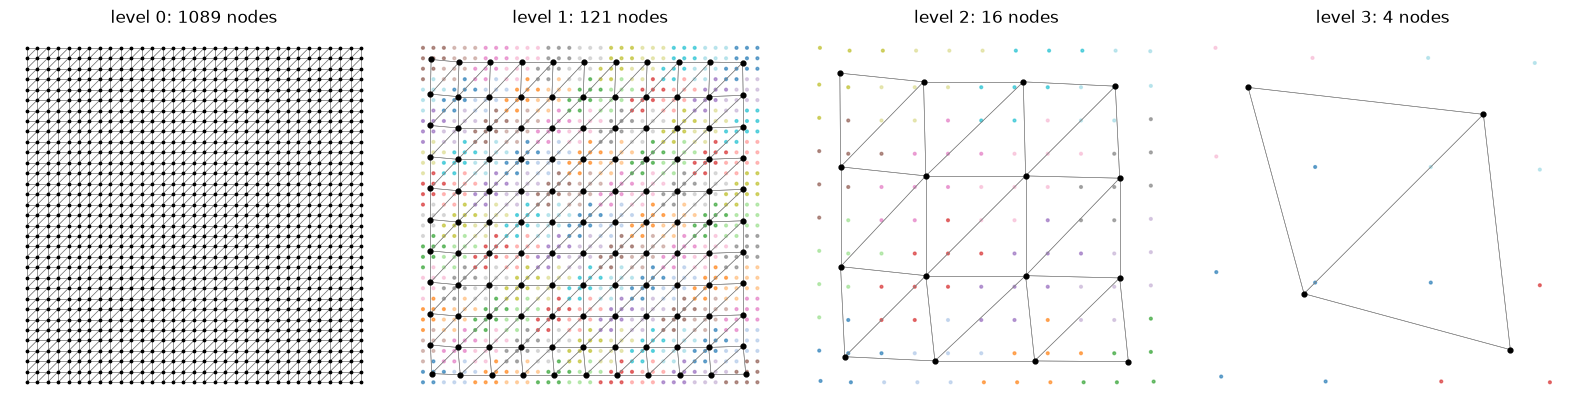

In [8]:
from multiscale_implementation.mesh.mesh_hierarchy import plot_hierarchy
plot_levels = [l.to('cpu') for l in level_list]
plot_hierarchy(levels=plot_levels, path="test.png")